In [2]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/nberry18/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

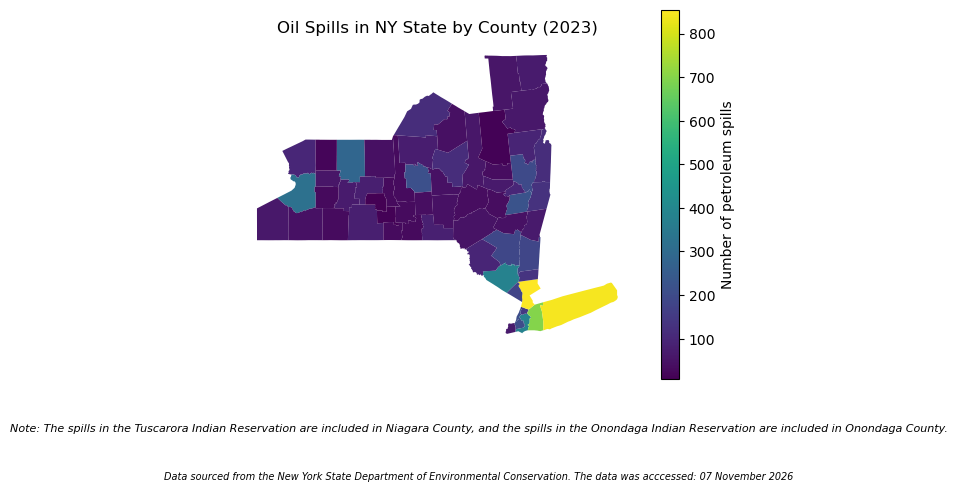

In [61]:
# FINAL CODE

# Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Data
fp = os.path.join('data', 'Spill_Incidents_20261107.csv')
spills = pd.read_csv(fp)

fp = os.path.join('data','tl_2026_us_county (2)', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

# Data Cleaning
spills.columns = spills.columns.str.strip().str.lower().str.replace(' ', '_')
spills['spill_date'] = pd.to_datetime(spills['spill_date'])

counties.columns = counties.columns.str.lower()
counties['statefp'] = counties['statefp'].astype(int)

# Data Selection
petr_23 = spills[
    (spills['spill_date'] >= '2023-01-01') & 
    (spills['spill_date'] <= '2023-12-31') & 
    (spills['material_family'] == 'Petroleum')]

spills_per_county = (petr_23.groupby('county')
                    .nunique()['spill_number']
                    .reset_index()
                    .rename(columns = {'spill_number':'n_spills'}))

ny_counties = counties[counties['statefp'] == 36]

spills_counties = spills_per_county['county'].unique()

ny_diff_counties = ny_counties['name'].unique()

ny_counties = ny_counties.rename(columns = {'name': 'county'})

# Merge
ny_spills = pd.merge(ny_counties, 
                     spills_per_county,
                     how = 'inner',
                     on = 'county')

spills_per_county['county'] = spills_per_county['county'].replace({ # replace() is for values inside of columns
'Tuscarora Indian Reservation': 'Niagara',
'Onondaga Indian Reservation': 'Onondaga'
})

spills_per_county = spills_per_county.groupby('county').sum().reset_index()

# Remerge spills_per_county and ny_counties
ny_spills = pd.merge(ny_counties,
    spills_per_county,
    how = 'inner',
    on = 'county')

# Map
fig, ax = plt.subplots()

#Create a choropleth map of ny_spills

ny_spills.plot(ax = ax, 
                   column = 'n_spills', # this parameter indicates which column to color by
                    legend = True,
                    legend_kwds = {'label': 'Number of petroleum spills'},
                    cmap = 'viridis'
                    )

ax.axis('off')

ax.set_title('Oil Spills in NY State by County (2023)', fontsize = 12)

plt.figtext(0.5, 0.0, 'Note: The spills in the Tuscarora Indian Reservation are included in Niagara County, and the spills in the Onondaga Indian Reservation are included in Onondaga County.',
    ha = 'center', fontsize = 8, style = 'italic')

plt.figtext(0.5, -0.10, 'Data sourced from the New York State Department of Environmental Conservation. The data was acccessed: 07 November 2026',
    ha = 'center', fontsize = 7, style = 'italic')

plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [23]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [24]:
# load in datasets
fp = os.path.join('data', 'Spill_Incidents_20261107.csv')
spills = pd.read_csv(fp)


fp = os.path.join('data','tl_2026_us_county (2)', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [25]:
#a. Check the dataframe's head
print(spills.head()) # head() first few rows of df

   Spill Number Program Facility Name                  Street 1 Street 2  \
0        107132                MH 864        RT 119/MILLWOOD RD      NaN   
1        405586             BOWRY BAY        WATER POLL CONTROL      NaN   
2        405586             BOWRY BAY        WATER POLL CONTROL      NaN   
3        204667            POLE 16091       GRACE AVE/BURKE AVE      NaN   
4        210559               POLE ON  FERDALE LOMIS RD / RT 52      NaN   

   Locality       County ZIP Code  SWIS Code  DEC Region  Spill Date  \
0  ELMSFORD  Westchester      NaN       6000           3  10/10/2001   
1    QUEENS       Queens      NaN       4101           2  08/21/2004   
2    QUEENS       Queens      NaN       4101           2  08/21/2004   
3     BRONX        Bronx      NaN        301           2  08/02/2002   
4   LIBERTY     Sullivan      NaN       5336           3  01/20/2003   

  Received Date Contributing Factor   Waterbody                 Source  \
0    10/10/2001             Unknown 

In [26]:
#b. Check the data types of the columns
print(spills.dtypes) # data types, look for wrong datatypes for columns

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object


In [27]:
#c. Check the unique values in the `material_family` column
spills["Material Family"].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [28]:
#d. Check the unique values in the `county` column
spills["County"].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

In [29]:
# Number of unique values for Spill Number column
spills['Spill Number'].nunique()

544781

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [30]:
# Change all column names to lower case and repalce spaces with '-'
spills.columns = spills.columns.str.strip().str.lower().str.replace(' ', '_')

spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [31]:
# Convert column data type to datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date']) # now able to pull out certain months and years
spills['spill_date']

0        2001-10-10
1        2004-08-21
2        2004-08-21
3        2002-08-02
4        2003-01-20
            ...    
574850   2004-04-27
574851   1999-07-06
574852   1993-03-02
574853   1990-01-05
574854   2001-06-13
Name: spill_date, Length: 574855, dtype: datetime64[ns]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [32]:
# Creating a dataframe with all requirements met
petr_23 = spills[
    (spills['spill_date'] >= '2023-01-01') & 
    (spills['spill_date'] <= '2023-12-31') & 
    (spills['material_family'] == 'Petroleum')]

petr_23

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,NaN,BURDETT,Schuyler,14818,4926,8,2023-12-08,12/08/2023,Traffic Accident,NaN,Tank Truck,12/18/2024,diesel,Petroleum,300,Gallons,0
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,diesel,Petroleum,0,NaN,0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,#2 fuel oil,Petroleum,0,Gallons,0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,gasoline,Petroleum,0,NaN,0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574442,2307849,ZIMINSKI RESIDENCE,1892 BEECH ST,NaN,WANTAGH,Nassau,11793,3020,1,2023-12-26,12/26/2023,Equipment Failure,NaN,Private Dwelling,12/26/2023,#2 fuel oil,Petroleum,0.5,Gallons,0
574454,2208304,ZIMMERMAN - UST,19 MOUNTAIN AVENUE,NaN,LARCHMONT,Westchester,NaN,6032,3,2023-01-10,01/10/2023,Equipment Failure,NaN,Private Dwelling,NaN,#2 fuel oil,Petroleum,0,NaN,0
574567,2307406,ZIZIC - UST,4 AUTUMN RIDGE RD,NaN,POUND RIDGE,Westchester,NaN,6046,3,2023-12-07,12/07/2023,Equipment Failure,NaN,Private Dwelling,12/19/2023,#2 fuel oil,Petroleum,0,NaN,0
574747,2301301,ZULTOWSKY - UST,514 PELHAM MANOR RD,NaN,PELHAM,Westchester,NaN,6044,3,2023-05-16,05/16/2023,Equipment Failure,NaN,Private Dwelling,07/11/2023,#2 fuel oil,Petroleum,0,NaN,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [33]:
# print() and f-string to confirm the corect year and months are in the df
print(f"petr_23 includes data from {petr_23['spill_date'].dt.year.unique()}.")
print(f"petr_23 includes data from {petr_23['spill_date'].dt.month.unique()} months in 2023.")

petr_23 includes data from [2023].
petr_23 includes data from [12  6  8  9  7  1  2  3 11 10  5  4] months in 2023.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [34]:
# Assert message if no output, it is true statement
assert petr_23['material_family'].nunique() == 1

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [19]:
print(f"The number of rows in petr_23 is {len(petr_23)}.")
print(f"The number of unique spills in spill_number is {petr_23['spill_number'].nunique()}.")

The number of rows in petr_23 is 8468.
The number of unique spills in spill_number is 8228.


_These numbers are not the same because the is repeat spill numbers since the second string produces fewer number of values compared to the total number of rows in the petr_23 df._

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [35]:
# 
spills_per_county = (petr_23.groupby('county') # groupby coutry
                    .nunique()['spill_number'] # all of the unique values of spill number
                    .reset_index() # change index to the spill number
                    .rename(columns = {'spill_number':'n_spills'})) # change column name

spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [36]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [37]:
# a head() finds first few rows of df
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [38]:
# b dtypes finds all of the data types of columns 
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [39]:
# c checking crs of geospatial data
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

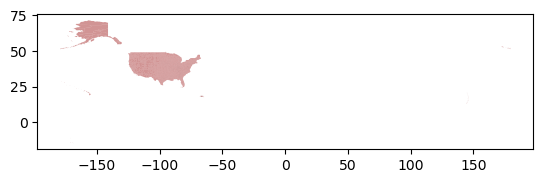

In [40]:
# d plot the counties data
fig, ax = plt.subplots()

# Add pigs point plot to our figure's axes
counties.plot(ax=ax, # Add plot to specific axes
              alpha = 0.5, # Control frequency
              color = 'brown') # Update point color

# Display
plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [41]:
# clean column names by making them all lower case and update datatype
counties.columns = counties.columns.str.lower()
counties['statefp'] = counties['statefp'].astype(int) # change this colum to int

In [42]:
counties['statefp'] 

0       12
1        6
2       18
3       35
4       10
        ..
3230    56
3231    55
3232    21
3233    19
3234    28
Name: statefp, Length: 3235, dtype: int64

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

<Axes: >

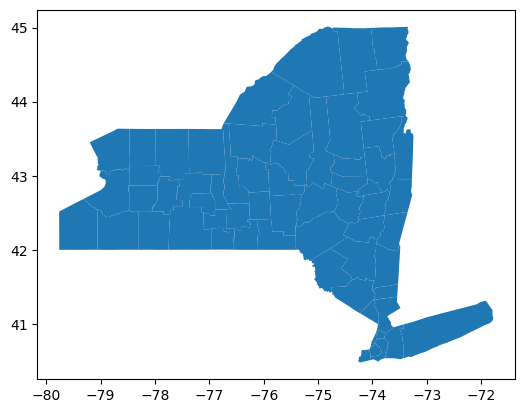

In [43]:
# Select only ny counties 
ny_counties = counties[counties['statefp'] == 36] # New York is #36

ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [44]:
# Only select the unique values
ny_diff_counties = ny_counties['name'].unique()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [45]:
# Unique counties 
spills_counties = spills_per_county['county'].unique()

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [46]:
# Check what county names that are in spills_counties, but not in ny_counties
diff_names_spills = np.setdiff1d(spills_counties, ny_diff_counties) # compares the values in both df
diff_names_spills

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [47]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [48]:
# Check what county names that are in ny_counties and not in spills_counties
diff_names_ny = np.setdiff1d(ny_diff_counties, spills_counties) # compares the values in both df
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [49]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [50]:
# e. Number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation
print(spills_per_county[(spills_per_county['county']=='Tuscarora Indian Reservation')]) # checking the number of Tuscarora Indian Reservation
print(spills_per_county[(spills_per_county['county']=='Onondaga Indian Reservation')])

                          county  n_spills
58  Tuscarora Indian Reservation         2
                         county  n_spills
35  Onondaga Indian Reservation         1


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [51]:
# Checking 'St Lawrence'
spills_per_county[spills_per_county['county'] == 'St Lawrence']

# Resetting 'St Lawrence' to 'St. Lawrence'
spills_per_county['county'] = spills_per_county['county'].replace({'St Lawrence': 'St. Lawrence'})

# Double check that 'St. Lawrence' is in spills_per_county['county']
spills_per_county[spills_per_county['county'].str.contains("St. Lawrence")]

# Assert to double 
assert spills_per_county.loc[52, 'county'] == "St. Lawrence", f"The update was not successful, the county name is {spills_per_countyloc[52, 'county']}"

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [52]:
# a Seeing where these columns intersect
common_columns = set(ny_counties.columns).intersection(spills_per_county.columns)

# Check to see if there is any common columns
if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else: 
    print("No common columns")

No common columns


In [53]:
# Rename column so they hae a common column 
ny_counties = ny_counties.rename(columns = {'name': 'county'})

# Seeing where these columns intersect after update
common_columns = set(ny_counties.columns).intersection(spills_per_county.columns)

# Check to see if there is any common columns
if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else: 
    print("No common columns")

Common columns: {'county'}


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [54]:
# Inner join spills_per_county and ny_counties
ny_spills = pd.merge(ny_counties, 
                     spills_per_county,
                     how = 'inner',
                     on = 'county') # merge on 'county' column

ny_spills

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518...",32
58,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508...",44
59,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713...",27
60,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111...",55


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [55]:
# Findng the number of columns in each df
print(f"Counties in spills_per_county: {len(spills_per_county)}")
print(f"Countries in ny_spills: {len(ny_spills)}")

# Removed counties
removed_counties = spills_per_county[~spills_per_county['county'].isin(ny_counties['county'])] 
removed_counties

Counties in spills_per_county: 66
Countries in ny_spills: 62


,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

_Type your answer here, replacing this text._

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [56]:
# Change 'Tuscarora Indian Reservation' to 'Niagara' and 'Onondaga Indian Reservation' to 'Onondaga' so I can add to other df
spills_per_county['county'] = spills_per_county['county'].replace({ # replace() is for values inside of columns
'Tuscarora Indian Reservation': 'Niagara',
'Onondaga Indian Reservation': 'Onondaga'
})

# Group rows by county and add their spill counts into a single row per county (each county is a row)
spills_per_county = spills_per_county.groupby('county').sum().reset_index()

# Remerge spills_per_county and ny_counties
ny_spills = pd.merge(ny_counties,
    spills_per_county,
    how = 'inner',
    on = 'county') # merge on column

ny_spills

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",99
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518...",32
58,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508...",44
59,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713...",27
60,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111...",55


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



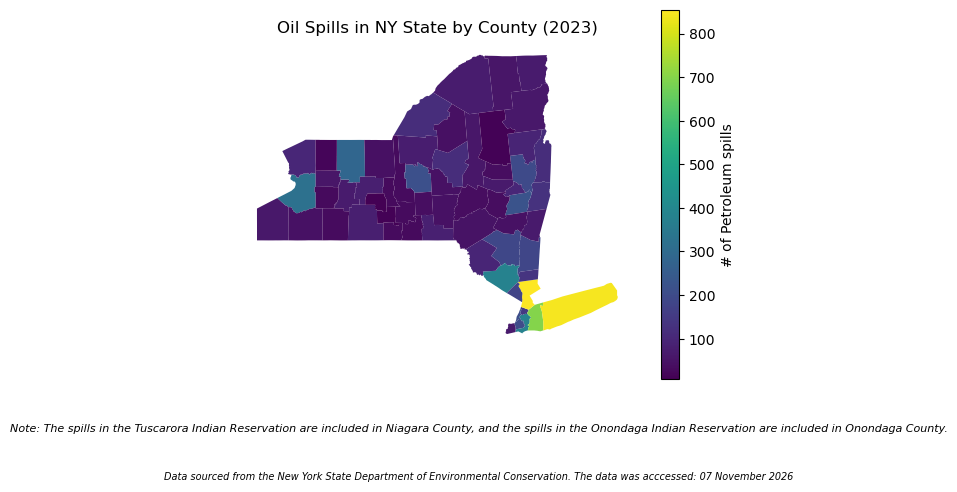

In [57]:
# Begin figure
fig, ax = plt.subplots()

#Create a choropleth map of ny_spills

ny_spills.plot(ax = ax, 
                   column = 'n_spills', # this parameter indicates which column to color by
                    legend = True, # Show legend
                    legend_kwds = {'label': '# of Petroleum spills'},
                    cmap = 'viridis' # color gradient
                    )

ax.axis('off') # remove axis

# Title
ax.set_title('Oil Spills in NY State by County (2023)', fontsize = 12)

# Setting text/ note
plt.figtext(0.5, 0.0, 'Note: The spills in the Tuscarora Indian Reservation are included in Niagara County, and the spills in the Onondaga Indian Reservation are included in Onondaga County.',
    ha = 'center', fontsize = 8, style = 'italic')

# Setting text/ note
plt.figtext(0.5, -0.10, 'Data sourced from the New York State Department of Environmental Conservation. The data was acccessed: 07 November 2026',
    ha = 'center', fontsize = 7, style = 'italic')

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

This project initially began with data cleaning standardizing all column names converting them to lowercase and ensuring that data types were appropriate, including converting the ‘spill_date’ column to a datetime format. This made the datasets consistent and easier to work with throughout the analysis. The counties dataset was subsetted to include only New York counties. Before merging ‘setdiff1d()’ was used to identify differences in county names between the datasets and determine which records would not successfully match. The counties data set was the base of the merge so the spills data only merged spill data for New York counties. Later it showed that Tuscarora Indian Reservation and Onondaga Indian Reservation were not included, and I manually added them to the Niagara and Onondaga counties so they could be included in the analysis.

The map summarizes the merged oil spill data and New York counties showing the distribution of petroleum spills across counties in New York State. The most southern county in New York had the highest number of oil spills around 800. Most of the counties range from 100-200 oil spills. 

It is important to note that the reassignment of the Tuscarora and Onondaga Indian Reservation records represents a data-cleaning decision that may influence the results. These reservations contributed only one or two spill incidents each to counties that already contained many spill records. Without documentation of this decision, a reader could incorrectly assume that the reservations themselves experienced more petroleum spills than were actually reported. This consideration also underscores the importance of the CARE Principles in data analysis. Researchers should clearly disclose any modifications made during data cleaning and highlight how those decisions may affect the interpretation of results.


## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.